<a href="https://colab.research.google.com/github/mohammedEhab2235/Car-rental-/blob/main/European_soccer_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import sqlite3
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

conn = sqlite3.connect('last2.db')
matches = pd.read_sql("SELECT * FROM vw_team_match_stats", conn)
matches_2 = pd.read_sql("SELECT * FROM vw_matches WHERE B365H IS NOT NULL", conn)
team_attrs = pd.read_sql("SELECT * FROM vw_team_latest_attributes", conn)
player_attrs = pd.read_sql("SELECT * FROM vw_player_latest_attributes", conn)
squad_strength = pd.read_sql("SELECT * FROM vw_match_squad_strength", conn)
player_info = pd.read_sql("SELECT * FROM Player", conn)
summery=pd.read_sql("SELECT * FROM vw_team_season_summary", conn)
player_age_ratting=pd.read_sql("SELECT * FROM vw_player_age_ratings", conn)

##in this chart explains that home matches wins and goals are lot more than away goals and wins

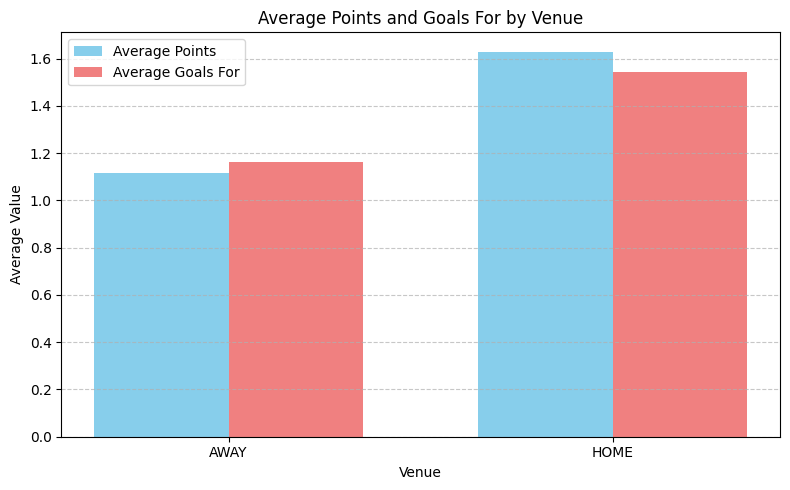

In [ ]:
# Group by venue and calculate the average of 'points' and 'goals_for'
average_stats_by_venue = matches.groupby('venue')[['points', 'goals_for']].mean().reset_index()

# Plotting the results
fig, ax = plt.subplots(figsize=(8, 5))

bar_width = 0.35
index = range(len(average_stats_by_venue['venue']))

bar1 = ax.bar(index, average_stats_by_venue['points'], bar_width, label='Average Points', color='skyblue')
bar2 = ax.bar([i + bar_width for i in index], average_stats_by_venue['goals_for'], bar_width, label='Average Goals For', color='lightcoral')

ax.set_xlabel('Venue')
ax.set_ylabel('Average Value')
ax.set_title('Average Points and Goals For by Venue')
ax.set_xticks([i + bar_width / 2 for i in index])
ax.set_xticklabels(average_stats_by_venue['venue'])
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

##so here wehen we test to see the coloretion , there will be absloute relate between home and wininng

In [ ]:
# Aggregate matches to team-season points
team_season_points = matches.groupby(['team_api_id', 'season'])['points'].sum().reset_index()
team_season_points.rename(columns={'points': 'total_season_points'}, inplace=True)

# Merge with team_attrs
# Assuming team_attrs has the latest attributes for each team_api_id
# We will use a left merge to keep all team attributes and add season points where available
merged_df = pd.merge(team_season_points,
                            team_attrs,
                            on='team_api_id',
                            how='left')

print("Aggregated team-season points and merged with team attributes:")
print(merged_df.head())

Aggregated team-season points and merged with team attributes:
   team_api_id     season  total_season_points      id  team_fifa_api_id  \
0         1601  2008/2009                   34  1118.0             874.0   
1         1601  2009/2010                   53  1118.0             874.0   
2         1601  2010/2011                   38  1118.0             874.0   
3         1601  2011/2012                   55  1118.0             874.0   
4         1601  2012/2013                   31  1118.0             874.0   

                  date  buildUpPlaySpeed buildUpPlaySpeedClass  \
0  2015-09-10 00:00:00              47.0              Balanced   
1  2015-09-10 00:00:00              47.0              Balanced   
2  2015-09-10 00:00:00              47.0              Balanced   
3  2015-09-10 00:00:00              47.0              Balanced   
4  2015-09-10 00:00:00              47.0              Balanced   

   buildUpPlayDribbling buildUpPlayDribblingClass  ...  \
0                  48.0  

In [ ]:
# Identify numerical team attributes for correlation analysis
# Exclude identifier columns like 'id', 'team_fifa_api_id', 'team_api_id', and 'date'
numerical_cols = [
    'buildUpPlaySpeed',
    'buildUpPlayDribbling',
    'buildUpPlayPassing',
    'chanceCreationPassing',
    'chanceCreationCrossing',
    'chanceCreationShooting',
    'defencePressure',
    'defenceAggression',
    'defenceTeamWidth',
    'total_season_points'
]

# Filter out columns that might not exist or are not numerical, and also handle potential NaNs
# Use .select_dtypes(include=np.number) to ensure only numeric columns are selected
import numpy as np
corr_df = merged_df[numerical_cols].select_dtypes(include=np.number)

# Calculate the correlation matrix
correlation_matrix = corr_df.corr()

# Extract correlations with 'total_season_points'
correlation_with_points = correlation_matrix['total_season_points'].sort_values(ascending=False)

print("Correlation of team attributes with Total Season Points:")
print(correlation_with_points)

Correlation of team attributes with Total Season Points:
total_season_points       1.000000
defencePressure           0.303998
defenceAggression         0.289278
defenceTeamWidth          0.113941
buildUpPlaySpeed          0.029303
chanceCreationPassing     0.019263
buildUpPlayDribbling      0.014163
chanceCreationShooting    0.002596
chanceCreationCrossing   -0.014162
buildUpPlayPassing       -0.199689
Name: total_season_points, dtype: float64


```markdown
### Interpretation of Correlations:

*   **Positive Correlation:** Attributes with positive correlation values tend to increase as `total_season_points` increase. For example, a higher `buildUpPlaySpeed` might be associated with more points.
*   **Negative Correlation:** Attributes with negative correlation values tend to decrease as `total_season_points` increase. For example, a lower `defencePressure` might be associated with more points (though this would depend on the interpretation of the attribute).
*   **Magnitude:** The closer the absolute value of the correlation is to 1, the stronger the relationship.

This output helps identify which team attributes have the strongest linear relationships with a team's total points in a season.
```

Text(0.5, 1.0, 'Correlation Heatmap')

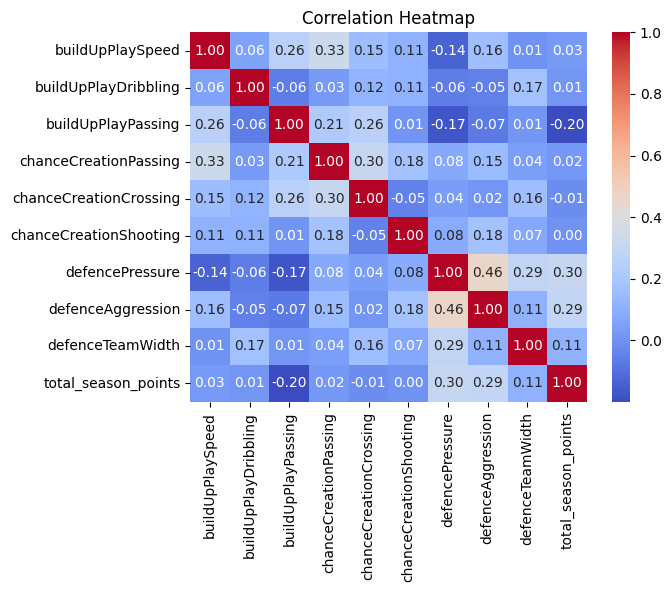

In [ ]:
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap')

In [ ]:
print (merged_df.head())

   team_api_id     season  total_season_points      id  team_fifa_api_id  \
0         1601  2008/2009                   34  1118.0             874.0   
1         1601  2009/2010                   53  1118.0             874.0   
2         1601  2010/2011                   38  1118.0             874.0   
3         1601  2011/2012                   55  1118.0             874.0   
4         1601  2012/2013                   31  1118.0             874.0   

                  date  buildUpPlaySpeed buildUpPlaySpeedClass  \
0  2015-09-10 00:00:00              47.0              Balanced   
1  2015-09-10 00:00:00              47.0              Balanced   
2  2015-09-10 00:00:00              47.0              Balanced   
3  2015-09-10 00:00:00              47.0              Balanced   
4  2015-09-10 00:00:00              47.0              Balanced   

   buildUpPlayDribbling buildUpPlayDribblingClass  ...  \
0                  48.0                    Normal  ...   
1                  48.0       

##Squad strength vs actual points Chart

/tmp/ipykernel_640/3786865248.py:58: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  hero_df_cleaned.loc[:, 'predicted_points'] = model.predict(X)
/tmp/ipykernel_640/3786865248.py:59: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  hero_df_cleaned.loc[:, 'residuals'] = hero_df_cleaned['total_season_points'] - hero_df_cleaned['predicted_points']


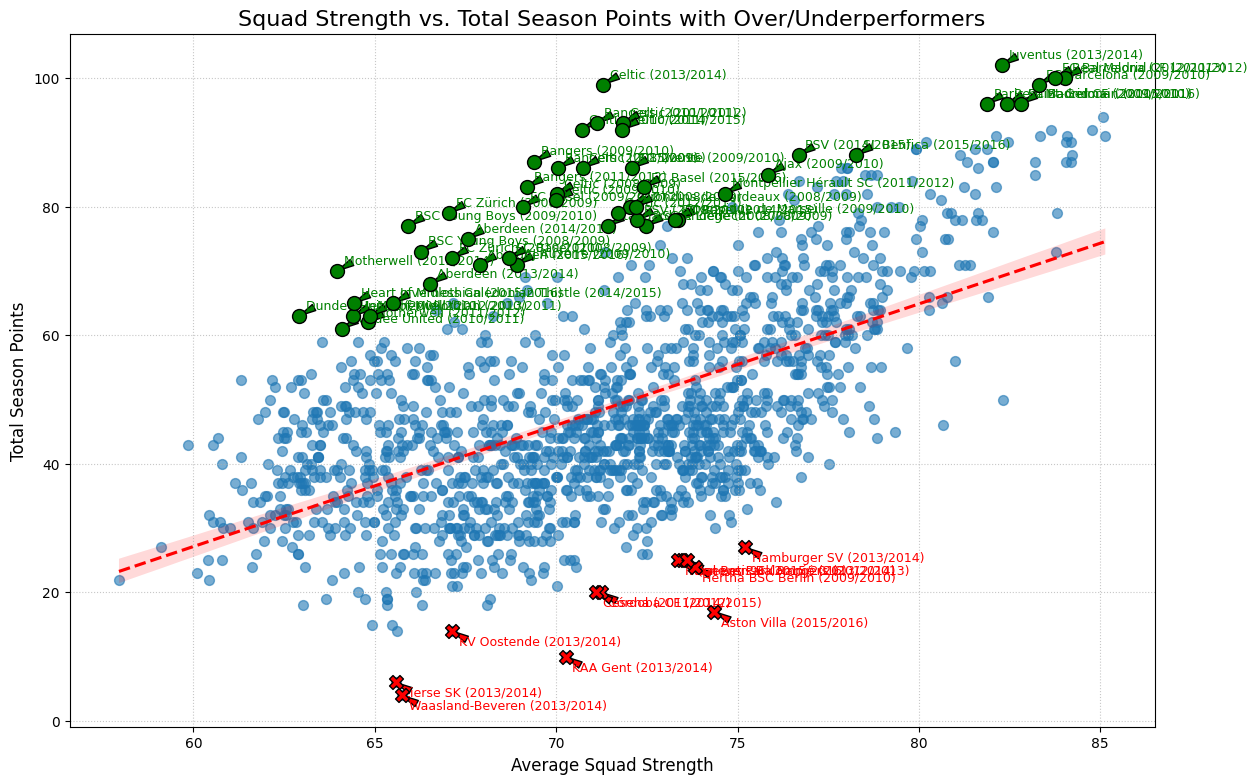

In [ ]:
from sklearn.linear_model import LinearRegression

# Rename the column at index 5 in squad_strength to 'strength_overall'
# This addresses the KeyError: 'Column not found: strength_overall'
# Based on the kernel state, squad_strength has 7 columns, and the 6th (index 5) contains numerical strength values.
if len(squad_strength.columns) > 5 and squad_strength.columns[5] != 'strength_overall':
    squad_strength = squad_strength.rename(columns={squad_strength.columns[5]: 'strength_overall'})

# Merge squad_strength with matches to get season information
# This assumes 'matches' has a 'season' column that aligns with 'squad_strength' entries.
# squad_strength already has match_api_id, team_api_id and match_date.
# We need to link squad_strength entries to their respective seasons.
# The 'matches' DataFrame has 'match_api_id' and 'season'.

# Create a mapping from match_api_id to season, dropping duplicates if any match_api_id has multiple seasons (unlikely).
match_season_map = matches[['match_api_id', 'season']].drop_duplicates()

squad_strength_with_season = pd.merge(
    squad_strength,
    match_season_map,
    on='match_api_id',
    how='left'
)

# Aggregate squad_strength to team-season level
aggregated_squad_strength = squad_strength_with_season.groupby(['team_api_id', 'season'])['strength_overall'].mean().reset_index()
aggregated_squad_strength.rename(columns={'strength_overall': 'avg_squad_strength'}, inplace=True)

# Merge with team_season_points (which is available from previous cells)
hero_df = pd.merge(
    team_season_points,
    aggregated_squad_strength,
    on=['team_api_id', 'season'],
    how='inner' # Use inner merge to only keep seasons where both data exist
)

# Merge with team_attrs to get team names
# Assuming team_attrs contains unique team_api_id and team_long_name.
hero_df = pd.merge(
    hero_df,
    team_attrs[['team_api_id', 'team_long_name']].drop_duplicates(subset=['team_api_id']),
    on='team_api_id',
    how='left'
)

# Drop rows with NaN in the columns we're using for regression and plotting
hero_df_cleaned = hero_df.dropna(subset=['avg_squad_strength', 'total_season_points', 'team_long_name'])

# Fit a linear regression model
model = LinearRegression()
X = hero_df_cleaned[['avg_squad_strength']]
y = hero_df_cleaned['total_season_points']
model.fit(X, y)

# Get predicted values and residuals
hero_df_cleaned.loc[:, 'predicted_points'] = model.predict(X)
hero_df_cleaned.loc[:, 'residuals'] = hero_df_cleaned['total_season_points'] - hero_df_cleaned['predicted_points']

# Define outlier threshold (e.g., 2 standard deviations)
residual_std = hero_df_cleaned['residuals'].std()
outlier_threshold = 2 * residual_std

# Identify overperformers and underperformers
overperformers = hero_df_cleaned[hero_df_cleaned['residuals'] > outlier_threshold].copy()
underperformers = hero_df_cleaned[hero_df_cleaned['residuals'] < -outlier_threshold].copy()

plt.figure(figsize=(14, 9))
sns.regplot(data=hero_df_cleaned, x='avg_squad_strength', y='total_season_points',
            scatter_kws={'alpha':0.6, 's':50}, line_kws={'color':'red', 'linestyle':'--'})

plt.title('Squad Strength vs. Total Season Points with Over/Underperformers', fontsize=16)
plt.xlabel('Average Squad Strength', fontsize=12)
plt.ylabel('Total Season Points', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.7)

# Label outliers on the plot
for i, row in overperformers.iterrows():
    plt.annotate(
        f"{row['team_long_name']} ({row['season']})",
        (row['avg_squad_strength'], row['total_season_points']),
        textcoords="offset points",
        xytext=(5,5),
        ha='left',
        fontsize=9,
        color='green',
        arrowprops=dict(facecolor='green', shrink=0.05, width=1, headwidth=5)
    )

    # Add a marker for the overperformer point
    plt.scatter(row['avg_squad_strength'], row['total_season_points'], color='green', marker='o', s=100, edgecolors='black', zorder=5)

for i, row in underperformers.iterrows():
    plt.annotate(
        f"{row['team_long_name']} ({row['season']})",
        (row['avg_squad_strength'], row['total_season_points']),
        textcoords="offset points",
        xytext=(5,-10),
        ha='left',
        fontsize=9,
        color='red',
        arrowprops=dict(facecolor='red', shrink=0.05, width=1, headwidth=5)
    )

    # Add a marker for the underperformer point
    plt.scatter(row['avg_squad_strength'], row['total_season_points'], color='red', marker='X', s=100, edgecolors='black', zorder=5)

plt.show()

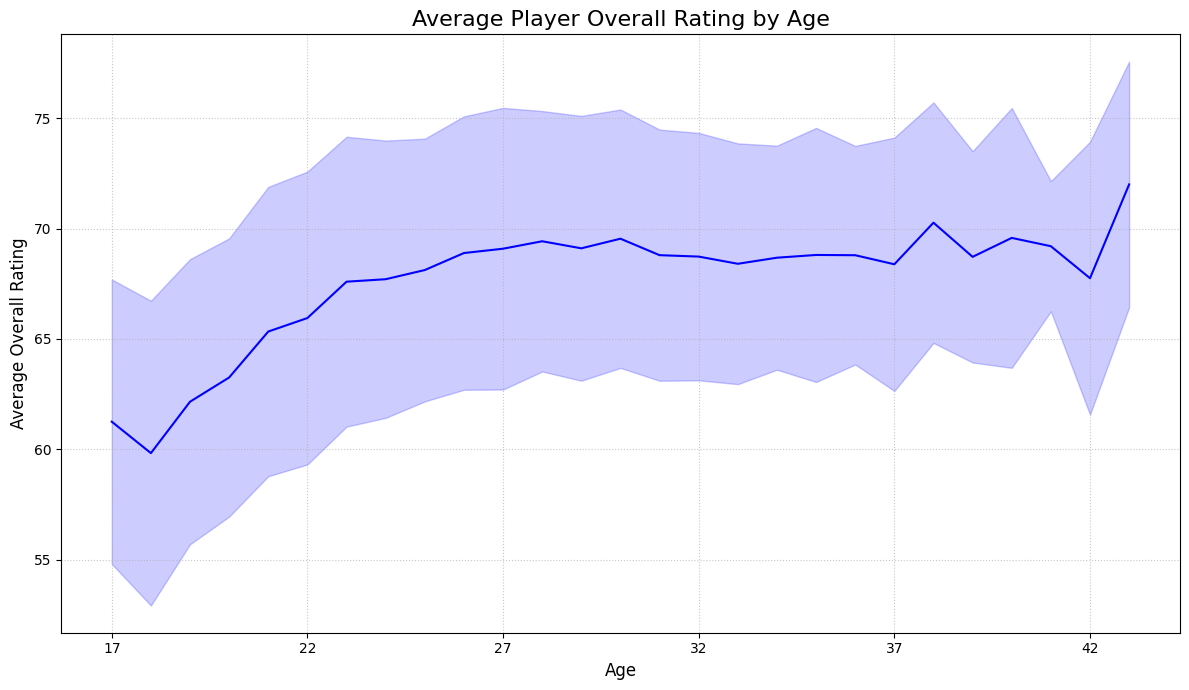

In [ ]:
# Merge player_attrs with player_info to get the 'birthday' column
player_attrs_merged = pd.merge(player_attrs, player_info[['player_api_id', 'birthday']], on='player_api_id', how='left')

# Convert 'birthday' and 'date' to datetime objects
player_attrs_merged['birthday'] = pd.to_datetime(player_attrs_merged['birthday'])
player_attrs_merged['date'] = pd.to_datetime(player_attrs_merged['date'])

# Calculate age at the time of the attribute date
player_attrs_merged['age'] = (player_attrs_merged['date'] - player_attrs_merged['birthday']).dt.days / 365.25
player_attrs_merged['age'] = player_attrs_merged['age'].astype(int)

# Group by age and calculate the mean of overall_rating
age_overall_rating = player_attrs_merged.groupby('age')['overall_rating'].mean().reset_index()

plt.figure(figsize=(12, 7))
sns.lineplot(data=player_attrs_merged, x='age', y='overall_rating', errorbar='sd', markers=False, linestyle='-', color='blue')
plt.title('Average Player Overall Rating by Age', fontsize=16)
plt.xlabel('Age', fontsize=12)
plt.ylabel('Average Overall Rating', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.7)
plt.xticks(np.arange(player_attrs_merged['age'].min(), player_attrs_merged['age'].max() + 1, 5))
plt.tight_layout()
plt.show()


Exporting data to csv so that we can work on Power bi


In [ ]:

pd.read_sql("SELECT * FROM vw_team_match_stats", conn).to_csv('team_match_stats.csv', index=False)
pd.read_sql("SELECT * FROM vw_team_latest_attributes", conn).to_csv('team_attributes.csv', index=False)
pd.read_sql("SELECT * FROM vw_players_full", conn).to_csv('players_full.csv', index=False)
pd.read_sql("SELECT * FROM vw_match_squad_strength", conn).to_csv('squad_strength.csv', index=False)
pd.read_sql("SELECT * FROM vw_matches", conn).to_csv('matches.csv', index=False)
player_info = pd.read_sql("SELECT * FROM Player", conn).to_csv('player_info.csv', index=False)
pd.read_sql("SELECT * FROM vw_team_season_summary", conn).to_csv('team_season_summary.csv', index=False)
pd.read_sql("SELECT * FROM vw_player_age_ratings", conn).to_csv('player_age_ratings.csv', index=False)

In [ ]:

# implied probability from decimal odds
matches_2['implied_prob_home'] = 1 / matches_2['B365H']

# bucket into 10% bands (0-10%, 10-20%, ... 90-100%)
matches_2['prob_bucket'] = (np.floor(matches_2['implied_prob_home'] * 10) / 10).round(2)

matches_2['is_home_win'] = (matches_2['result'] == 'HOME_WIN').astype(int)

calibration = matches_2.groupby('prob_bucket').agg(
    actual_win_rate=('is_home_win', 'mean'),
    n_matches_2=('is_home_win', 'count'),
    avg_implied_prob=('implied_prob_home', 'mean')
).reset_index()

# the diagonal reference: perfect calibration means actual = predicted
calibration['perfect_calibration'] = calibration['prob_bucket']

calibration.to_csv('odds_calibration.csv', index=False)
print(calibration)

   prob_bucket  actual_win_rate  n_matches_2  avg_implied_prob  \
0          0.0         0.037559          213          0.077193   
1          0.1         0.141727         1390          0.147937   
2          0.2         0.238636         2200          0.250687   
3          0.3         0.322519         3144          0.348196   
4          0.4         0.423350         5636          0.442910   
5          0.5         0.523064         4596          0.542495   
6          0.6         0.614135         2462          0.652599   
7          0.7         0.734385         1521          0.743199   
8          0.8         0.830536         1251          0.835090   
9          0.9         0.944134          179          0.924544   

   perfect_calibration  
0                  0.0  
1                  0.1  
2                  0.2  
3                  0.3  
4                  0.4  
5                  0.5  
6                  0.6  
7                  0.7  
8                  0.8  
9                  0.9 